# Part 4.F — Visual analysis and failure cases

This notebook compares the three Part 4 systems on the **same** test images:

* **ResNet-18 GAP 896-D + linear SVM** (Stage A cache);
* **DINOv2 CLS 384-D + linear SVM** (Stage B cache);
* **CLIP ViT-B/32 zero-shot** with the prompt bank selected in Stage E.

It produces:

1. a shared case set (high-confidence correct, near-boundary correct, false
   positive, false negative, model disagreement);
2. per-model error galleries;
3. architecture-appropriate saliency maps:
   * ResNet-18: **Grad-CAM** of the SVM decision score on `layer4`;
   * DINOv2: **patch-token similarity** (to CLS and to a class prototype);
   * CLIP: **patch–text similarity** from the projected patch tokens;
4. quantitative diagnostics: per-class AP, three-model agreement, and the
   background rejection rate;
5. a manual-review template for the qualitative part (focus on object vs
   context, error taxonomy).

**Honesty note.** Saliency shows which pixels correlate with the classifier’s
score; it does not prove causal reasoning. The dataset ships no bounding boxes,
so “inside the object” is assessed visually on the shared case set, not with a
fabricated quantitative mask.

In [1]:
import json
import os
import sys
from pathlib import Path


def _find_code_dir():
    '''Locate the directory containing src/ (works from code/ or the repo root).'''
    here = Path.cwd().resolve()
    for base in [here, *here.parents]:
        for candidate in (base, base / "code"):
            if (candidate / "src" / "deep_models.py").exists():
                return candidate
    raise FileNotFoundError(
        "Could not find src/deep_models.py. Open the notebook from code/ or the repo root."
    )


CODE_DIR = _find_code_dir()
if str(CODE_DIR) not in sys.path:
    sys.path.insert(0, str(CODE_DIR))
os.chdir(CODE_DIR)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from PIL import Image
from sklearn.metrics import average_precision_score
from torchvision import transforms

from src.deep_eval import (
    BACKGROUND,
    CATEGORIES,
    DEFAULT_C_GRID,
    binary_subset,
    evaluate_binary,
    l2norm,
    save_results,
    train_svm_checked,
)
from src.deep_features import FEATURE_ROOT, load_feature_cache
from src.deep_models import getModel
from src.utils import loadSamplesTable

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

# --------------------------- experiment configuration -----------------------
FEATURE_SPECS = {
    "cnn": dict(tag="resnet18_gap896", key="features"),
    "dinov2": dict(tag="dinov2_vits14", key="features_cls"),
    "clip": dict(tag="clip_vit_b_32", key="features_clip"),
}
CASE_CATEGORIES = ("motorbike", "person")
MAX_ITER = 10000
SEED = 0
C_GRID = DEFAULT_C_GRID
# Stage A concatenates GAP(layer2.1)=128, GAP(layer3.1)=256, GAP(layer4.1)=512.
CNN_GAP_SLICES = {"layer2": slice(0, 128), "layer3": slice(128, 384),
                  "layer4": slice(384, 896)}

RESULTS_DIR = Path("results")
FIG_DIR = RESULTS_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams["figure.dpi"] = 110
np.random.seed(SEED)

IMAGENET_MEAN = np.array([0.485, 0.456, 0.406])
IMAGENET_STD = np.array([0.229, 0.224, 0.225])
CLIP_MEAN = np.array([0.48145466, 0.4578275, 0.40821073])
CLIP_STD = np.array([0.26862954, 0.26130258, 0.27577711])

Device: cpu


## F.1 — Load the three feature caches on one canonical row order

`loadSamplesTable` defines the canonical order; every cache is reordered to it by
file name, so scores, labels and image paths cannot silently drift.

In [2]:
train_df = loadSamplesTable("data/splits", "data/images", subset="train", per_class=-1)
test_df = loadSamplesTable("data/splits", "data/images", subset="val", per_class=-1)
train_names = train_df.filename.to_numpy().astype(str)
test_names = test_df.filename.to_numpy().astype(str)
train_categories = train_df.category.to_numpy().astype(str)
test_categories = test_df.category.to_numpy().astype(str)

features = {"train": {}, "val": {}}
for model_name, spec in FEATURE_SPECS.items():
    for subset, names in (("train", train_names), ("val", test_names)):
        feats, _, _ = load_feature_cache(
            spec["tag"], subset, spec["key"], target_names=names)
        features[subset][model_name] = l2norm(feats)
        print(f"{model_name:<7s} {subset}: {feats.shape}")

val_path = RESULTS_DIR / "part4_internal_val_names.csv"
if not val_path.exists():
    raise FileNotFoundError(
        f"{val_path} is missing. Run Stage A/B first to persist the shared split."
    )
val_names = pd.read_csv(val_path, dtype={"file_name": str})["file_name"].to_numpy()
assert np.isin(train_names, val_names).any(), "shared split does not match the caches"
assert not np.isin(test_names, val_names).any(), "internal-val and test overlap"
print(f"train={len(train_names)}  internal-val={len(val_names)}  test={len(test_names)}")

cnn     train: (2791, 896)
cnn     val: (2796, 896)
dinov2  train: (2791, 384)
dinov2  val: (2796, 384)
clip    train: (2791, 512)
clip    val: (2796, 512)
train=2791  internal-val=558  test=2796


## F.2 — Refit the supervised heads and load CLIP zero-shot scores

The SVM is refitted from the cached descriptors (fast) with `C` selected on the
shared internal validation split, exactly as in Stages A/B. The CLIP bank comes
from `data/deep_features/clip_vit_b_32/selected_text_bank.npz` (written by Stage E).

In [3]:
svm_summaries = {"cnn": [], "dinov2": []}
svm_scores = {"cnn": {}, "dinov2": {}}       # full test-row scores, NaN outside pos/bg
svm_weights = {"cnn": {}, "dinov2": {}}

for model_name in ("cnn", "dinov2"):
    X_train = features["train"][model_name]
    X_test = features["val"][model_name]
    for cat in CATEGORIES:
        X_tr, y_tr, n_tr = binary_subset(cat, X_train, train_names, train_categories)
        X_te, y_te, n_te = binary_subset(cat, X_test, test_names, test_categories)
        summary, sweep, test_scores = evaluate_binary(
            cat, X_tr, y_tr, n_tr, X_te, y_te, val_names,
            C_grid=C_GRID, max_iter=MAX_ITER, seed=SEED,
        )
        W, b, *_ = train_svm_checked(
            X_tr, y_tr, float(summary["C"]), max_iter=MAX_ITER, seed=SEED)

        pos_idx = np.flatnonzero(test_categories == cat)
        neg_idx = np.flatnonzero(test_categories == BACKGROUND)
        full = np.full(len(test_names), np.nan)
        full[np.r_[pos_idx, neg_idx]] = test_scores

        svm_summaries[model_name].append(summary)
        svm_scores[model_name][cat] = full
        svm_weights[model_name][cat] = (W, b)
        flag = "" if summary["converged"] else "  [not converged]"
        print(f"{model_name:<7s} {cat:<10s} C={summary['C']:<6g} "
              f"test AP={summary['test_ap']:.4f}{flag}")

for model_name in ("cnn", "dinov2"):
    df = pd.DataFrame(svm_summaries[model_name])
    print(f"{model_name} mAP: {df.test_ap.mean():.4f}")
    save_results(df, RESULTS_DIR / f"part4f_{model_name}_per_class.csv")

# --------------------------- CLIP zero-shot ---------------------------------
bank_path = FEATURE_ROOT / FEATURE_SPECS["clip"]["tag"] / "selected_text_bank.npz"
if not bank_path.exists():
    raise FileNotFoundError(
        f"{bank_path} is missing. Run `7_clip_zero_shot.ipynb` first."
    )
with np.load(bank_path, allow_pickle=True) as data:
    text_bank = data["embeddings"]
    bank_labels = data["categories"].astype(str)
    CLIP_PROMPT_SET = str(data["prompt_set"][0])

X_test_clip = features["val"]["clip"]
clip_all = X_test_clip @ text_bank.T          # (N, 6)
clip_scores = {cat: clip_all[:, list(bank_labels).index(cat)] for cat in CATEGORIES}
clip_bg_score = clip_all[:, list(bank_labels).index(BACKGROUND)]

clip_rows = []
for cat in CATEGORIES:
    mask = (test_categories == cat) | (test_categories == BACKGROUND)
    y = (test_categories[mask] == cat).astype(int)
    clip_rows.append(dict(category=cat, dim=512, prompt_set=CLIP_PROMPT_SET,
                          test_ap=float(average_precision_score(y, clip_scores[cat][mask]))))
clip_df = pd.DataFrame(clip_rows)
print(f"CLIP zero-shot ({CLIP_PROMPT_SET}) mAP: {clip_df.test_ap.mean():.4f}")
save_results(clip_df, RESULTS_DIR / "part4f_clip_zero_shot_per_class.csv")
display(clip_df.round(4).reset_index(drop=True))

cnn     aeroplane  C=10     test AP=0.9723
cnn     car        C=1      test AP=0.9646
cnn     horse      C=10     test AP=0.9568
cnn     motorbike  C=10     test AP=0.9809
cnn     person     C=1      test AP=0.9739
dinov2  aeroplane  C=0.1    test AP=1.0000
dinov2  car        C=1      test AP=0.9749
dinov2  horse      C=0.1    test AP=0.9980
dinov2  motorbike  C=10     test AP=0.9818
dinov2  person     C=1      test AP=0.9820
cnn mAP: 0.9697
dinov2 mAP: 0.9873
CLIP zero-shot (label_only) mAP: 0.8401


,category,dim,prompt_set,test_ap
0,aeroplane,512,label_only,0.9487
1,car,512,label_only,0.8648
2,horse,512,label_only,0.8991
3,motorbike,512,label_only,0.9434
4,person,512,label_only,0.5445


## F.3 — Shared case set

Cases are chosen with the **DINOv2** score as the reference, then reused for all
models. Five types per category:

| type | definition |
|---|---|
| `correct_high` | positive with the highest score |
| `correct_low` | positive with the lowest **positive** score (near boundary) |
| `false_negative` | positive with the lowest score |
| `false_positive` | background image with the highest score |
| `disagreement` | positive/background where CNN and DINOv2 signs differ most |

Images are deduplicated within a category.

In [4]:
def select_cases(cat, n_per_type=1):
    '''Return a list of dicts describing shared cases for one category.'''
    pos = np.flatnonzero(test_categories == cat)
    bg = np.flatnonzero(test_categories == BACKGROUND)
    s = svm_scores["dinov2"][cat]
    s_cnn = svm_scores["cnn"][cat]

    candidates = {
        "correct_high": pos[np.argsort(-s[pos])],
        "correct_low": pos[np.argsort(s[pos][s[pos] > 0])] if (s[pos] > 0).any()
                       else pos[np.argsort(-s[pos])],
        "false_negative": pos[np.argsort(s[pos])],
        "false_positive": bg[np.argsort(-s[bg])],
    }
    both = np.r_[pos, bg]
    disagree = (s_cnn[both] > 0).astype(int) != (s[both] > 0).astype(int)
    order = np.argsort(-np.abs(s_cnn[both] - s[both]))
    candidates["disagreement"] = (both[order][disagree[order]] if disagree.any()
                                  else pos[np.argsort(-s[pos])])

    used, rows = set(), []
    for case_type, ordered in candidates.items():
        for idx in ordered:
            if idx in used:
                continue
            used.add(int(idx))
            rows.append(dict(case_id=f"{cat}_{case_type}",
                             category=cat, case_type=case_type,
                             file_name=test_names[idx],
                             true_label=test_categories[idx],
                             cnn_score=float(svm_scores["cnn"][cat][idx]),
                             dinov2_score=float(svm_scores["dinov2"][cat][idx]),
                             clip_score=float(clip_scores[cat][idx])))
            break
    return rows


cases = []
for cat in CASE_CATEGORIES:
    cases.extend(select_cases(cat))
cases_df = pd.DataFrame(cases)
save_results(cases_df, RESULTS_DIR / "part4f_cases.csv")
display(cases_df.round(3).reset_index(drop=True))

,case_id,category,case_type,file_name,true_label,cnn_score,dinov2_score,clip_score
0,motorbike_correct_high,motorbike,correct_high,007897,motorbike,2.152,3.002,0.248
1,motorbike_correct_low,motorbike,correct_low,001199,motorbike,0.153,0.053,0.254
2,motorbike_false_negative,motorbike,false_negative,008742,motorbike,-1.133,-1.576,0.176
3,motorbike_false_positive,motorbike,false_positive,003808,background,-0.755,0.035,0.190
4,motorbike_disagreement,motorbike,disagreement,009894,background,0.182,-1.572,0.224
5,person_correct_high,person,correct_high,008241,person,2.755,3.580,0.223
6,person_correct_low,person,correct_low,003580,person,3.105,1.913,0.225
7,person_false_negative,person,false_negative,002361,person,-1.529,-1.616,0.215
8,person_false_positive,person,false_positive,003443,background,0.421,1.182,0.208
9,person_disagreement,person,disagreement,001509,person,-0.985,1.876,0.201


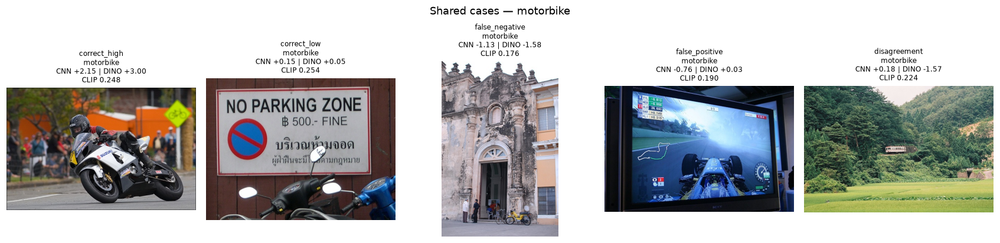

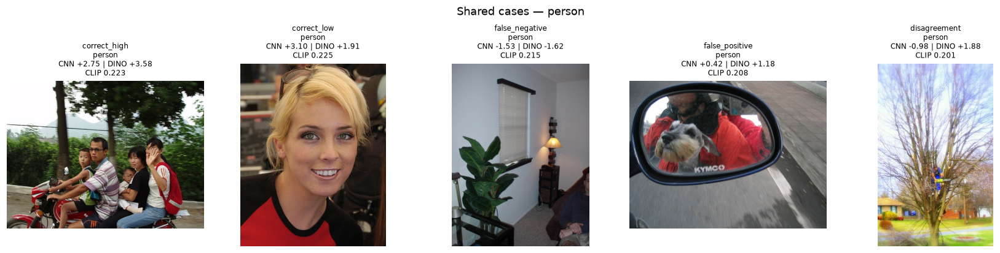

In [5]:
def show_image_grid(rows, path_fn):
    n = len(rows)
    fig, axes = plt.subplots(1, n, figsize=(3.1 * n, 3.6))
    axes = np.atleast_1d(axes)
    for ax, row in zip(axes, rows):
        image = Image.open(path_fn(row)).convert("RGB")
        ax.imshow(image)
        ax.axis("off")
        ax.set_title(
            f"{row['case_type']}\n{row['category']}\n"
            f"CNN {row['cnn_score']:+.2f} | DINO {row['dinov2_score']:+.2f}\n"
            f"CLIP {row['clip_score']:.3f}",
            fontsize=8,
        )
    plt.tight_layout()
    return fig


def image_path(row):
    name = row["file_name"] if isinstance(row, dict) else row.file_name
    return Path("data/images") / f"{name}.jpg"


for cat in CASE_CATEGORIES:
    rows = [row for row in cases if row["category"] == cat]
    fig = show_image_grid(rows, image_path)
    fig.suptitle(f"Shared cases — {cat}", y=1.03)
    fig.savefig(FIG_DIR / f"part4f_cases_{cat}.png", bbox_inches="tight")
    plt.show()

## F.4 — ResNet-18 Grad-CAM of the SVM score

The target is the SVM decision `W · GAP(layer4) + b`, not an ImageNet logit, so
the heatmap explains the *task* classifier. `layer4[-1]` is the final residual
block (7×7×512). Stage A’s 896-D descriptor concatenates GAP of layer2/3/4, so
the Grad-CAM uses the matching **layer4 slice** (`W[384:896]`); the gradient of
the full score with respect to layer4 is identical because only that slice
depends on layer4.

In [6]:
cnn_model, cnn_preprocess = getModel("resnet18", device)
cnn_model.eval()


def gradcam_svm(image_path, model, preprocess, W, b, layer):
    '''Return a 224x224 Grad-CAM for the linear score W·GAP(layer) + b.'''
    model.zero_grad(set_to_none=True)
    x = preprocess(Image.open(image_path).convert("RGB")).unsqueeze(0).to(device)

    store = {}

    def hook(module, inputs, output):
        output.retain_grad()
        store["activation"] = output

    handle = layer.register_forward_hook(hook)
    try:
        with torch.enable_grad():
            pooled = model(x)
            score = (pooled * torch.as_tensor(W, dtype=pooled.dtype, device=device)).sum() + b
            score.backward()
    finally:
        handle.remove()

    activation = store["activation"].detach()[0]
    gradient = store["activation"].grad.detach()[0]
    weights = gradient.mean(dim=(1, 2))
    cam = torch.relu((weights[:, None, None] * activation).sum(dim=0))
    cam = cam - cam.min()
    cam = cam / (cam.max() + 1e-8)
    cam = F.interpolate(cam[None, None], size=(224, 224),
                        mode="bilinear", align_corners=False)[0, 0]
    return cam.cpu().numpy()


def to_display(x, mean, std):
    '''Denormalise a CHW tensor for imshow.'''
    array = x.detach().cpu().numpy().transpose(1, 2, 0).copy()
    array = array * std + mean
    return np.clip(array, 0, 1)

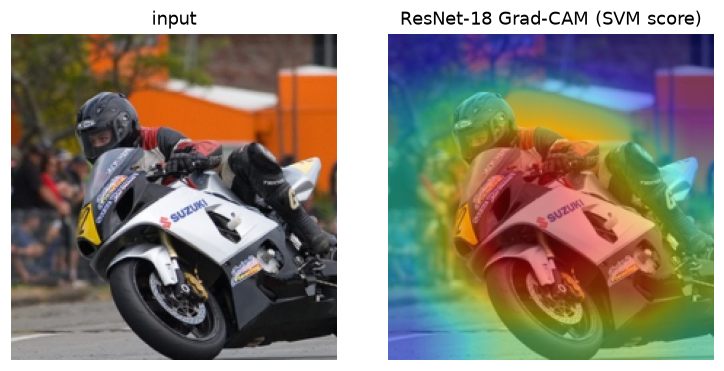

In [7]:
# quick visual check on one case
row = cases[0]
W, b = svm_weights["cnn"][row["category"]]
W_layer4 = W[CNN_GAP_SLICES["layer4"]]
cam = gradcam_svm(image_path(row), cnn_model, cnn_preprocess, W_layer4, b,
                  cnn_model.layer4[-1])
x_display = to_display(cnn_preprocess(Image.open(image_path(row)).convert("RGB")),
                       IMAGENET_MEAN, IMAGENET_STD)
fig, ax = plt.subplots(1, 2, figsize=(7, 3.4))
ax[0].imshow(x_display); ax[0].set_title("input"); ax[0].axis("off")
ax[1].imshow(x_display); ax[1].imshow(cam, cmap="jet", alpha=0.45)
ax[1].set_title("ResNet-18 Grad-CAM (SVM score)"); ax[1].axis("off")
plt.tight_layout()
plt.show()

## F.5 — DINOv2 and CLIP patch maps

* **DINOv2:** cosine similarity between each of the 16×16 patch tokens and
  (a) the CLS token, (b) the mean CLS descriptor of the class’s training
  positives (a class prototype).
* **CLIP:** patch tokens from the last transformer block, normalised with
  `ln_post` and projected with `visual.proj`, compared with the class text
  embedding. The grid is only 7×7, so the map is coarse.

In [8]:
dino_model, dino_preprocess = getModel("dinov2_vits14", device)
dino_model.eval()
clip_model, clip_preprocess = getModel("clip_vit_b_32", device)
clip_model.eval()

dino_prototypes = {}
for cat in CATEGORIES:
    pos = np.flatnonzero(train_categories == cat)
    proto = features["train"]["dinov2"][pos].mean(axis=0)
    dino_prototypes[cat] = proto / (np.linalg.norm(proto) + 1e-10)


def upsample_map(grid):
    tensor = torch.as_tensor(grid, dtype=torch.float32)[None, None]
    return F.interpolate(tensor, size=(224, 224), mode="bilinear",
                         align_corners=False)[0, 0].numpy()


def dino_patch_maps(image_path, model, preprocess, prototype):
    x = preprocess(Image.open(image_path).convert("RGB")).unsqueeze(0).to(device)
    with torch.inference_mode():
        out = model.forward_features(x)
        cls = out["x_norm_clstoken"][0]
        patches = out["x_norm_patchtokens"][0]
    patches = F.normalize(patches, dim=-1)
    side = int(round(patches.shape[0] ** 0.5))
    cls_map = (patches @ F.normalize(cls, dim=0)).reshape(side, side).cpu().numpy()
    proto_map = (patches @ torch.as_tensor(prototype, dtype=patches.dtype,
                                           device=patches.device)
                 ).reshape(side, side).cpu().numpy()
    return upsample_map(cls_map), upsample_map(proto_map)


def clip_patch_map(image_path, model, preprocess, text_embedding):
    store = {}

    def hook(module, inputs, output):
        store["tokens"] = output.detach()

    handle = model.visual.transformer.resblocks[-1].register_forward_hook(hook)
    try:
        x = preprocess(Image.open(image_path).convert("RGB")).unsqueeze(0).to(device)
        with torch.inference_mode():
            _ = model.encode_image(x)
    finally:
        handle.remove()

    tokens = store["tokens"][:, 0, :]           # (1 + 49, 768)
    with torch.no_grad():
        tokens = model.visual.ln_post(tokens)
        patches = tokens[1:]
        if model.visual.proj is not None:
            patches = patches @ model.visual.proj.detach()
    patches = F.normalize(patches, dim=-1)
    text = torch.as_tensor(text_embedding, dtype=patches.dtype, device=patches.device)
    text = text / (text.norm() + 1e-10)
    side = int(round(patches.shape[0] ** 0.5))
    return upsample_map((patches @ text).reshape(side, side).cpu().numpy())


def normalise_map(array):
    low, high = float(array.min()), float(array.max())
    return (array - low) / (high - low + 1e-8)

Using cache found in C:\Users\HP/.cache\torch\hub\facebookresearch_dinov2_main
c:\Users\HP\miniconda3\envs\cvc-a2\Lib\site-packages\torch\jit\_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


## F.6 — Side-by-side saliency for the shared cases

One row per case, five columns: input, ResNet Grad-CAM, DINOv2 CLS similarity,
DINOv2 class-prototype similarity, CLIP patch–text similarity. The same crops
used by each model are shown, so the overlays are aligned with the input the
model actually saw.

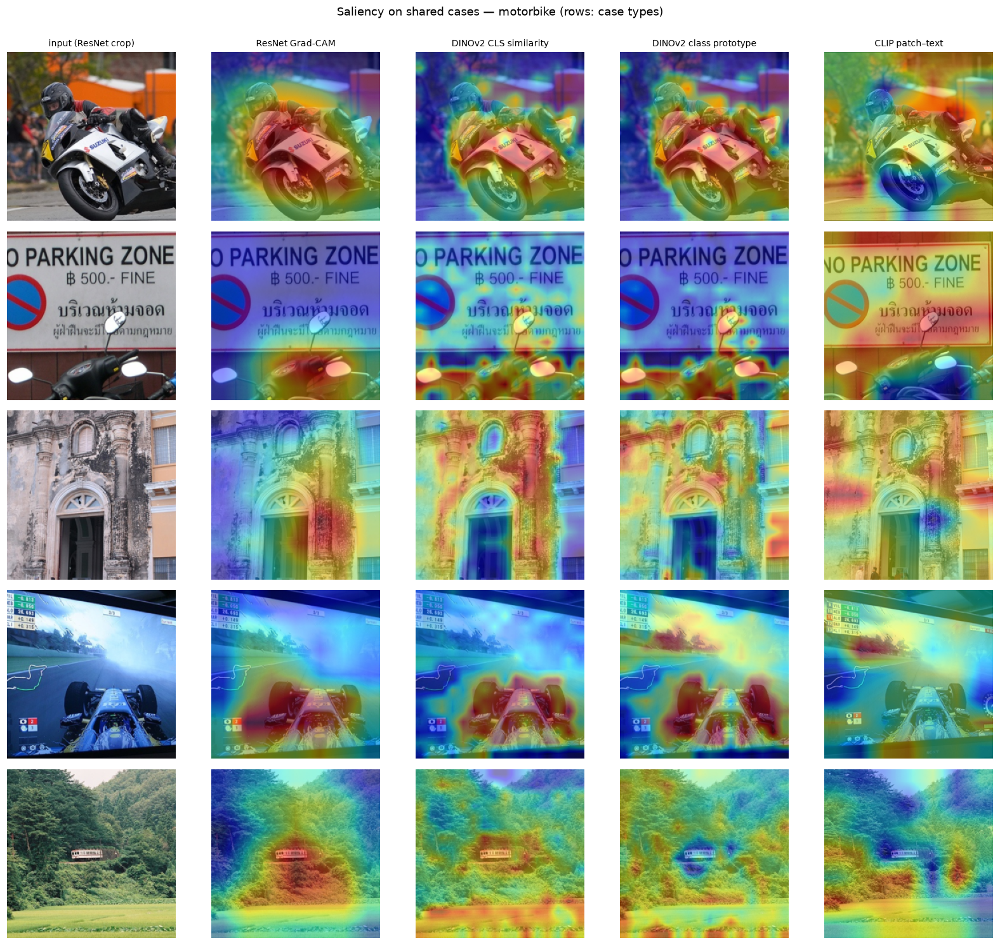

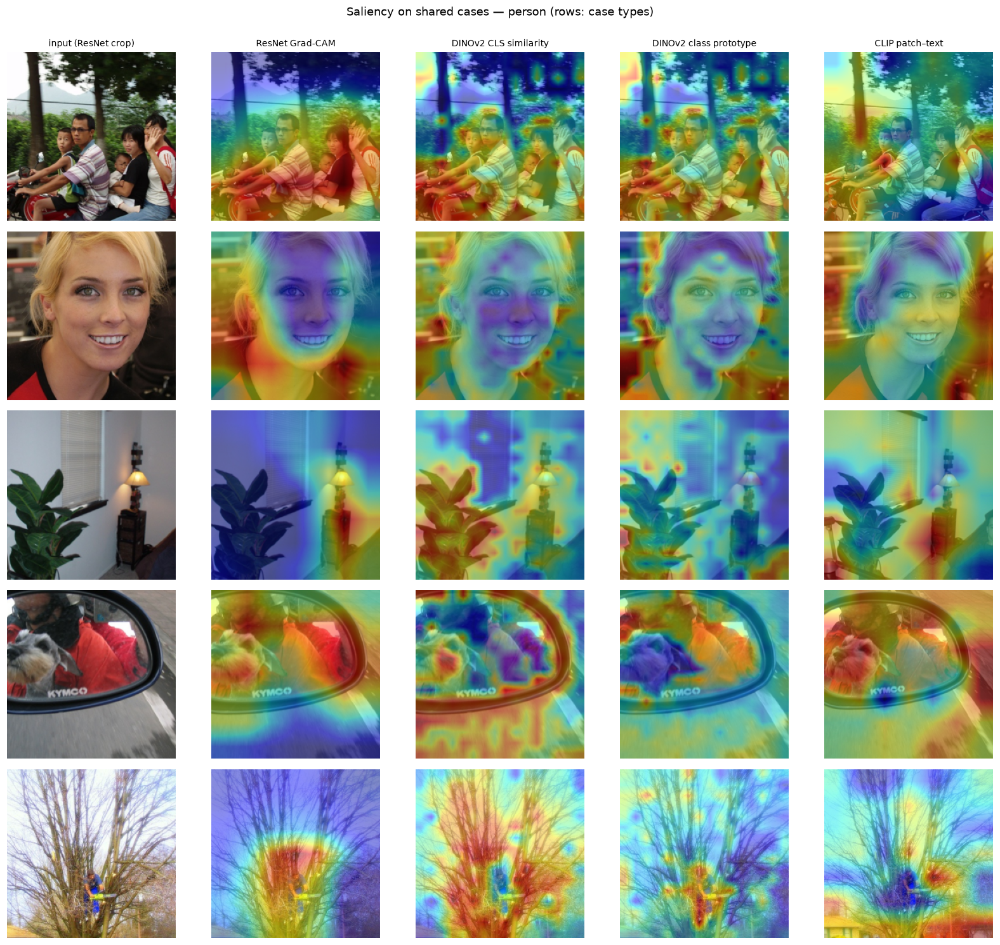

In [9]:
def saliency_row(row):
    path = image_path(row)
    W, b = svm_weights["cnn"][row["category"]]
    W_layer4 = W[CNN_GAP_SLICES["layer4"]]
    cam = gradcam_svm(path, cnn_model, cnn_preprocess, W_layer4, b,
                      cnn_model.layer4[-1])
    dino_cls, dino_proto = dino_patch_maps(
        path, dino_model, dino_preprocess, dino_prototypes[row["category"]])
    text = text_bank[list(bank_labels).index(row["category"])]
    clip_map = clip_patch_map(path, clip_model, clip_preprocess, text)

    cnn_img = to_display(cnn_preprocess(Image.open(path).convert("RGB")),
                         IMAGENET_MEAN, IMAGENET_STD)
    clip_img = to_display(clip_preprocess(Image.open(path).convert("RGB")),
                          CLIP_MEAN, CLIP_STD)
    return cnn_img, cam, dino_cls, dino_proto, clip_img, clip_map


for cat in CASE_CATEGORIES:
    rows = [row for row in cases if row["category"] == cat]
    fig, axes = plt.subplots(len(rows), 5, figsize=(15, 2.7 * len(rows)))
    axes = np.atleast_2d(axes)
    for r, row in enumerate(rows):
        cnn_img, cam, dino_cls, dino_proto, clip_img, clip_map = saliency_row(row)
        panels = [
            (cnn_img, None, "input (ResNet crop)"),
            (cnn_img, normalise_map(cam), "ResNet Grad-CAM"),
            (cnn_img, normalise_map(dino_cls), "DINOv2 CLS similarity"),
            (cnn_img, normalise_map(dino_proto), "DINOv2 class prototype"),
            (clip_img, normalise_map(clip_map), "CLIP patch–text"),
        ]
        for c, (image, overlay, title) in enumerate(panels):
            ax = axes[r, c]
            ax.imshow(image)
            if overlay is not None:
                ax.imshow(overlay, cmap="jet", alpha=0.45)
            ax.set_title(title if r == 0 else "", fontsize=9)
            ax.axis("off")
        axes[r, 0].set_ylabel(row["case_type"], fontsize=9)
    fig.suptitle(f"Saliency on shared cases — {cat} (rows: case types)", y=1.0)
    plt.tight_layout()
    fig.savefig(FIG_DIR / f"part4f_saliency_{cat}.png", bbox_inches="tight")
    plt.show()

## F.7 — Error galleries per model

For each category, three columns per model: highest-scoring background (false
positive), lowest-scoring positive (false negative), highest-scoring positive
(true positive). Rows are the three systems.

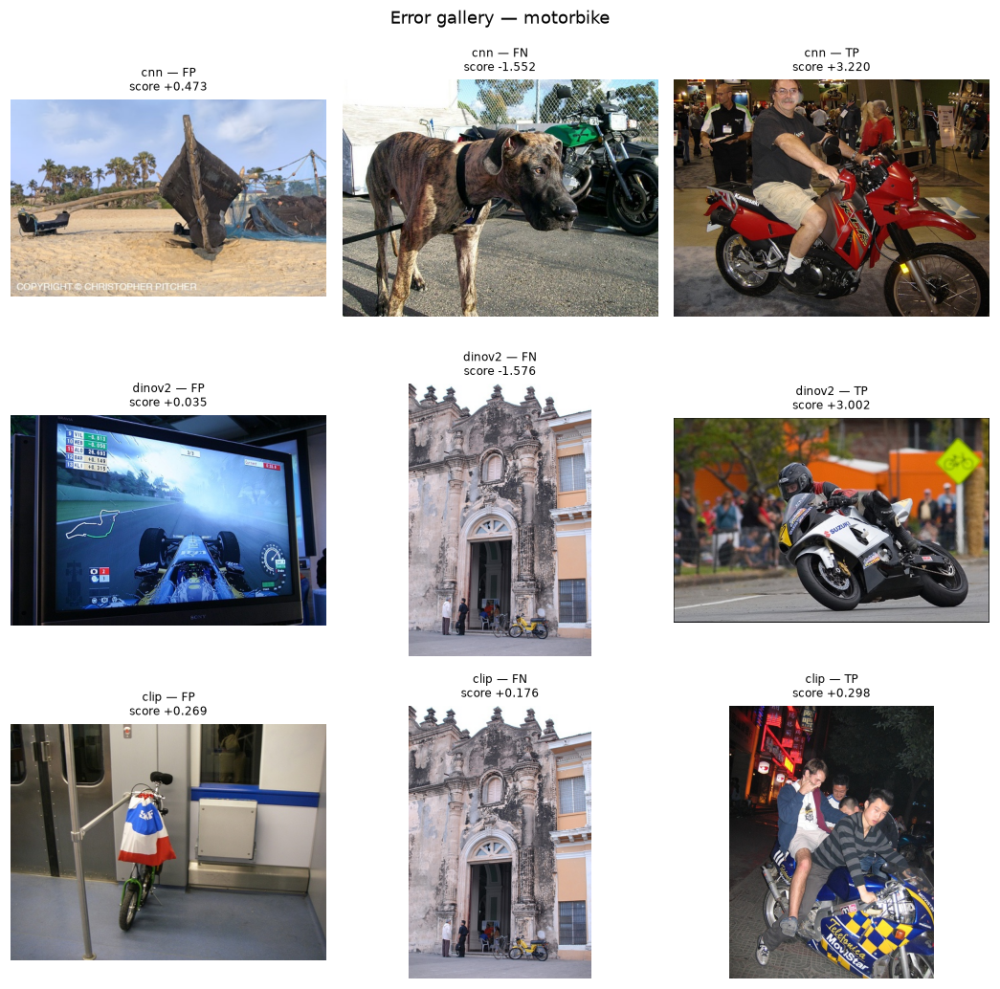

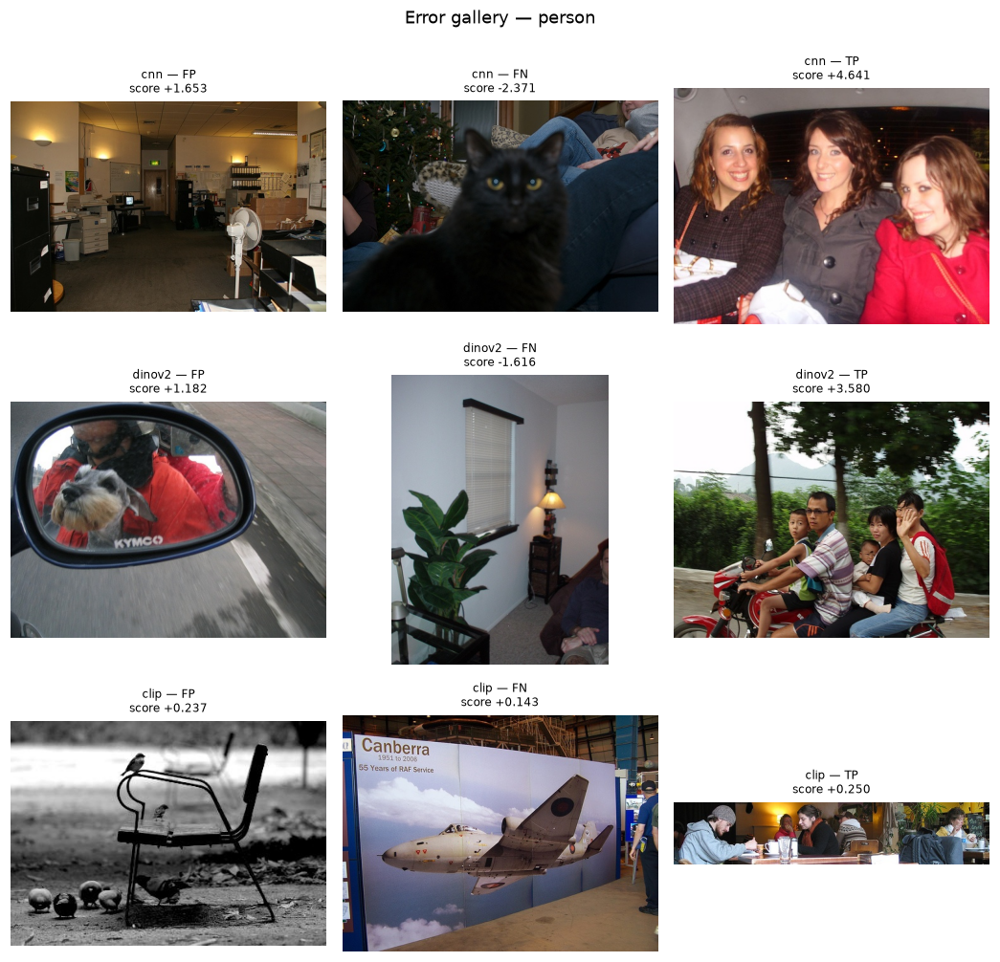

In [10]:
def top_indices(scores, cat, n=3):
    pos = np.flatnonzero(test_categories == cat)
    bg = np.flatnonzero(test_categories == BACKGROUND)
    s = scores[cat] if isinstance(scores, dict) else scores
    return {
        "FP": bg[np.argsort(-s[bg])[:n]],
        "FN": pos[np.argsort(s[pos])[:n]],
        "TP": pos[np.argsort(-s[pos])[:n]],
    }


for cat in CASE_CATEGORIES:
    fig, axes = plt.subplots(3, 3, figsize=(9.6, 9.4))
    for r, model_name in enumerate(("cnn", "dinov2", "clip")):
        scores = svm_scores[model_name] if model_name != "clip" else clip_scores
        picks = top_indices(scores, cat, n=1)
        for c, (kind, indices) in enumerate(picks.items()):
            idx = int(indices[0])
            ax = axes[r, c]
            ax.imshow(Image.open(Path("data/images") / f"{test_names[idx]}.jpg").convert("RGB"))
            ax.axis("off")
            score = (scores[cat] if model_name != "clip" else scores[cat])[idx]
            ax.set_title(f"{model_name} — {kind}\nscore {score:+.3f}", fontsize=8)
    fig.suptitle(f"Error gallery — {cat}", y=0.995)
    plt.tight_layout()
    fig.savefig(FIG_DIR / f"part4f_errors_{cat}.png", bbox_inches="tight")
    plt.show()

## F.8 — Quantitative diagnostics

1. Per-class AP for CNN, DINOv2 and CLIP zero-shot (plus CLIP+SVM if Stage E ran).
2. Three-model agreement on the binary pos-vs-background task and the
   background rejection rate at threshold 0 (SVM) / background prompt (CLIP).

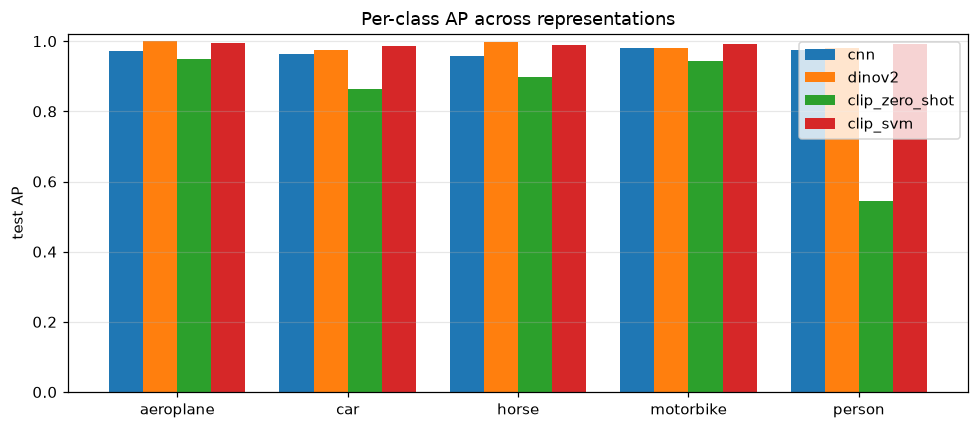

,category,cnn,dinov2,clip_zero_shot,clip_svm
0,aeroplane,0.9723,1.0000,0.9487,0.9961
1,car,0.9646,0.9749,0.8648,0.9869
2,horse,0.9568,0.9980,0.8991,0.9890
3,motorbike,0.9809,0.9818,0.9434,0.9933
4,person,0.9739,0.9820,0.5445,0.9929


In [11]:
per_class_rows = []
for cat in CATEGORIES:
    row = dict(category=cat)
    row["cnn"] = float(pd.DataFrame(svm_summaries["cnn"]).set_index("category").loc[cat, "test_ap"])
    row["dinov2"] = float(pd.DataFrame(svm_summaries["dinov2"]).set_index("category").loc[cat, "test_ap"])
    row["clip_zero_shot"] = float(clip_df.set_index("category").loc[cat, "test_ap"])
    per_class_rows.append(row)
per_class = pd.DataFrame(per_class_rows)

if (RESULTS_DIR / "part4e_clip_svm_per_class.csv").exists():
    clip_svm = pd.read_csv(RESULTS_DIR / "part4e_clip_svm_per_class.csv").set_index("category")
    per_class["clip_svm"] = [float(clip_svm.loc[cat, "test_ap"]) for cat in CATEGORIES]

save_results(per_class, RESULTS_DIR / "part4f_per_class_ap.csv")

fig, ax = plt.subplots(figsize=(9, 4))
cols = [c for c in ("cnn", "dinov2", "clip_zero_shot", "clip_svm") if c in per_class]
x = np.arange(len(per_class))
width = 0.8 / len(cols)
for i, col in enumerate(cols):
    ax.bar(x + i * width - 0.4 + width / 2, per_class[col], width, label=col)
ax.set_xticks(x, per_class.category)
ax.set_ylim(0, 1.02)
ax.set_ylabel("test AP")
ax.set_title("Per-class AP across representations")
ax.grid(axis="y", alpha=0.3)
ax.legend()
plt.tight_layout()
fig.savefig(FIG_DIR / "part4f_per_class_ap.png", bbox_inches="tight")
plt.show()
display(per_class.round(4).reset_index(drop=True))

In [12]:
def binary_predictions(cat):
    '''Return predicted labels (cat/background) for pos+bg rows, per model.'''
    pos = np.flatnonzero(test_categories == cat)
    bg = np.flatnonzero(test_categories == BACKGROUND)
    idx = np.r_[pos, bg]
    preds = {
        "cnn": np.where(svm_scores["cnn"][cat][idx] > 0, cat, BACKGROUND),
        "dinov2": np.where(svm_scores["dinov2"][cat][idx] > 0, cat, BACKGROUND),
        "clip": np.where(clip_scores[cat][idx] > clip_bg_score[idx], cat, BACKGROUND),
    }
    truth = np.where(np.isin(idx, pos), cat, BACKGROUND)
    return idx, truth, preds


agreement_rows = []
for cat in CATEGORIES:
    idx, truth, preds = binary_predictions(cat)
    all_agree = ((preds["cnn"] == preds["dinov2"]) &
                 (preds["dinov2"] == preds["clip"]))
    bg_rows = truth == BACKGROUND
    agreement_rows.append(dict(
        category=cat,
        all_three=float(all_agree.mean()),
        cnn_dinov2=float((preds["cnn"] == preds["dinov2"]).mean()),
        cnn_clip=float((preds["cnn"] == preds["clip"]).mean()),
        dinov2_clip=float((preds["dinov2"] == preds["clip"]).mean()),
        cnn_bg_rejection=float((preds["cnn"][bg_rows] == BACKGROUND).mean()),
        dinov2_bg_rejection=float((preds["dinov2"][bg_rows] == BACKGROUND).mean()),
        clip_bg_rejection=float((preds["clip"][bg_rows] == BACKGROUND).mean()),
    ))

agreement = pd.DataFrame(agreement_rows)
save_results(agreement, RESULTS_DIR / "part4f_agreement.csv")
display(agreement.round(4).reset_index(drop=True))

,category,all_three,cnn_dinov2,cnn_clip,dinov2_clip,cnn_bg_rejection,dinov2_bg_rejection,clip_bg_rejection
0,aeroplane,0.8562,0.9842,0.8587,0.8695,0.9944,1.0000,0.8561
1,car,0.8501,0.9653,0.8678,0.8670,0.9824,0.9898,0.9331
2,horse,0.8882,0.9812,0.8955,0.8996,0.9935,1.0000,0.8969
3,motorbike,0.9567,0.9875,0.9592,0.9667,0.9954,0.9991,0.9684
4,person,0.5320,0.9252,0.5762,0.5626,0.9656,0.9749,0.8682


## F.9 — Manual review template (object vs context, error taxonomy)

Fill `results/part4f_case_review.csv` after inspecting the galleries. Suggested
`focus` values: `object`, `context`, `ambiguous`. Suggested `error_type` values:

`small_object`, `occlusion_or_truncation`, `unusual_viewpoint`,
`class_ambiguity`, `background_contains_target`, `multiple_instances`,
`low_contrast_or_blur`, `label_noise`, `other`.

The cell below creates the template if it does not exist, and plots counts once
the columns are filled. The counts are *your* annotations; do not present them as
an automatic metric.

loaded results\part4f_case_review.csv (10 rows)


,case_id,category,case_type,file_name,cnn_score,dinov2_score,clip_score,focus,error_type,notes
0,motorbike_correct_high,motorbike,correct_high,7897,2.152036,3.002411,0.248293,object,NaN,NaN
1,motorbike_correct_low,motorbike,correct_low,1199,0.152895,0.052788,0.254217,ambiguous,NaN,NaN
2,motorbike_false_negative,motorbike,false_negative,8742,-1.133245,-1.576231,0.175681,context,NaN,NaN
3,motorbike_false_positive,motorbike,false_positive,3808,-0.755266,0.034530,0.189539,object,NaN,NaN
4,motorbike_disagreement,motorbike,disagreement,9894,0.182052,-1.571687,0.223513,context,NaN,NaN
5,person_correct_high,person,correct_high,8241,2.754911,3.580000,0.222905,object,NaN,NaN
6,person_correct_low,person,correct_low,3580,3.104607,1.912769,0.225356,ambiguous,NaN,NaN
7,person_false_negative,person,false_negative,2361,-1.528939,-1.615726,0.214959,context,NaN,NaN
8,person_false_positive,person,false_positive,3443,0.420604,1.181777,0.207683,object,NaN,NaN
9,person_disagreement,person,disagreement,1509,-0.984882,1.876346,0.200909,ambiguous,NaN,NaN


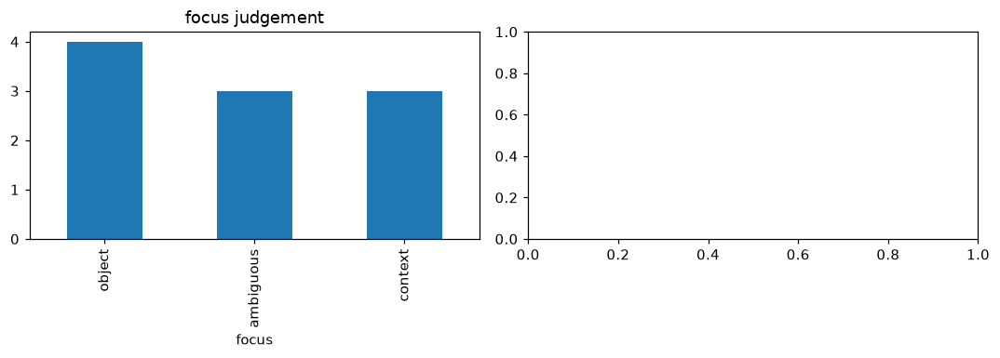

In [14]:
review_path = RESULTS_DIR / "part4f_case_review.csv"
review_cols = ["case_id", "category", "case_type", "file_name",
               "cnn_score", "dinov2_score", "clip_score",
               "focus", "error_type", "notes"]
if review_path.exists():
    review = pd.read_csv(review_path)
    print(f"loaded {review_path} ({len(review)} rows)")
else:
    review = cases_df.copy()
    for col in ("focus", "error_type", "notes"):
        review[col] = ""
    review = review[review_cols]
    save_results(review, review_path)
    print(f"created template {review_path}; fill focus/error_type/notes after inspection")

display(review)

filled_focus = review.focus.fillna("").astype(str).str.strip() != ""
filled_error = review.error_type.fillna("").astype(str).str.strip() != ""
if filled_focus.any() or filled_error.any():
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
    if filled_focus.any():
        review.loc[filled_focus, "focus"].value_counts().plot.bar(ax=axes[0])
        axes[0].set_title("focus judgement")
    if filled_error.any():
        review.loc[filled_error, "error_type"].value_counts().plot.bar(ax=axes[1])
        axes[1].set_title("error type")
        axes[1].tick_params(axis="x", rotation=45)
    plt.tight_layout()
    fig.savefig(FIG_DIR / "part4f_manual_review_counts.png", bbox_inches="tight")
    plt.show()
else:
    print("No annotations yet: fill the CSV, re-run this cell, then report the counts.")